# Construction du dataset CropYield Prediction

Assemblage des quatre fichiers sources en un dataset unique à la granularité
**pays × année × culture**, clé `iso3 + year + crop`, sur **1990-2013**.

Le notebook 03 a établi que `yield_df.csv`, le fichier pré-fusionné fourni, n'est pas
exploitable : 54 % de redondance due à un fan-out de `temp.csv`, et 101 pays seulement
du fait d'une jointure sur le nom littéral. On reconstruit donc.

| Décision | Motif |
|---|---|
| Période 1990-2013 | intersection des quatre sources |
| Jointure sur `iso3` | la jointure par nom littéral perd 19 pays, dont les États-Unis, la Chine et la Russie |
| `China, mainland` retenu | les trois sources explicatives ne décrivent que la Chine continentale |
| `temp.csv` dédoublonné puis moyenné | jusqu'à 41 relevés par pays-année, sinon fan-out |
| `rain_mm` conservée sans imputation | normale climatique par pays, qu'aucune valeur voisine ne permet d'inventer |
| Contrôle anti-fan-out après chaque jointure | c'est le contrôle qui manquait à `yield_df.csv` |

La logique est implémentée dans `src/data/crop_yield_prediction.py`, de façon à être
rejouable à l'identique par l'étape 2 et par l'API de l'étape 3.

# Imports

In [1]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))

from src import config, utils
from src.data import crop_yield_prediction as cyp

utils.style()

# Sources

In [2]:
brut = cyp.charge_sources()
for nom, df in brut.items():
    print(f"{nom:12s} {df.shape[0]:6,} lignes x {df.shape[1]} colonnes")

rendement    56,717 lignes x 12 colonnes
temperature  71,311 lignes x 3 colonnes
pluie         6,727 lignes x 3 colonnes
pesticides    4,349 lignes x 7 colonnes


# Préparation des sources

Chaque source est préparée séparément et renvoie le journal de ce qui lui a été
appliqué.

## Rendement

`China` est l'agrégat FAO incluant Taïwan, Hong Kong et Macao ; `China, mainland` est la
Chine continentale seule. Les trois sources explicatives ne décrivent que celle-ci : on
retient donc `China, mainland`, afin de joindre des périmètres comparables.

In [3]:
rendement, rapport = cyp.prepare_rendement(brut["rendement"])
print(rapport)
rendement.head()

              etape                                                                                                                               detail
      agregat Chine                                                                           448 lignes `China` ecartees au profit de `China, mainland`
              unite                                                                                                  hg/ha -> t/ha (division par 10 000)
          sans ISO3 321 lignes ecartees (entites historiques : URSS, Tchecoslovaquie, Belgique-Luxembourg, Yougoslavie, Serbie-et-Montenegro, Soudan ex)
doublons sur la cle                                                                                                                0 resolus par moyenne
             lignes                                                                                                                     56,717 -> 25,527


,iso3,area,year,crop,yield_t_ha
0,AFG,Afghanistan,1990,Maize,1.7582
1,AFG,Afghanistan,1991,Maize,1.6800
2,AFG,Afghanistan,1992,Maize,1.5000
3,AFG,Afghanistan,1993,Maize,1.6786
4,AFG,Afghanistan,1994,Maize,1.6667


## Température

C'est la source du fan-out. Doublons stricts retirés, relevés vides écartés, puis
moyenne par pays-année — sans pondération géographique, faute de métadonnée permettant
de départager les stations.

In [4]:
temperature, rapport = cyp.prepare_temperature(brut["temperature"])
print(rapport)
temperature.head()

                 etape                                                    detail
      doublons stricts                                      6958 lignes retirees
         releves vides                     1377 lignes sans temperature ecartees
releves par pays-annee jusqu'a 41 — c'est ce fan-out qui corrompt `yield_df.csv`
            agregation                        moyenne des releves par pays-annee
                lignes                                           71,311 -> 3,288


,iso3,year,avg_temp
0,AFG,1990,15.45
1,AFG,1991,14.57
2,AFG,1992,14.35
3,AFG,1993,14.96
4,AFG,1994,14.94


## Pluie

In [5]:
pluie, rapport = cyp.prepare_pluie(brut["pluie"])
print(rapport)
pluie.head()

             etape                                                                                                                            detail
        conversion                                                                                        780 valeurs non numeriques ou vides -> NaN
 annees aberrantes                                                          4 pays a plusieurs valeurs (ARG, BRB, IND, PRY) -> valeur modale retenue
series non fiables 11 pays ecartes (AGO, FSM, KIR, LIE, MHL, MNE, NRU, PLW, SRB, TUV, VUT) : serie entiere copiee du pays alphabetiquement precedent
         diffusion                                                                      1 valeur x 181 pays x 24 annees -> aucun trou, 2003 comprise
            lignes                                                                                                                    6,727 -> 4,344


,iso3,year,rain_mm
0,AFG,1990,327.0
1,AFG,1991,327.0
2,AFG,1992,327.0
3,AFG,1993,327.0
4,AFG,1994,327.0


## Pesticides

In [6]:
pesticides, rapport = cyp.prepare_pesticides(brut["pesticides"])
print(rapport)
pesticides.head()

 etape         detail
lignes 4,349 -> 3,810


,iso3,year,pesticides_t
0,AGO,1990,64.0
1,AGO,1991,79.0
2,AGO,1992,23.0
3,AGO,1993,169.0
4,AGO,1994,25.5


# Contrôles avant fusion

Avant de joindre quoi que ce soit, on vérifie que chaque source est **unique sur sa
clé**. C'est précisément cette vérification qui manquait à la construction de
`yield_df.csv`.

In [7]:
controle = cyp.controle_avant_fusion({
    "rendement": (rendement, cyp.CLE),
    "temperature": (temperature, ["iso3", "year"]),
    "pluie": (pluie, ["iso3", "year"]),
    "pesticides": (pesticides, ["iso3", "year"]),
})
controle

,source,lignes,pays,cle,doublons
0,rendement,25527,203,iso3 + year + crop,0
1,temperature,3288,137,iso3 + year,0
2,pluie,4344,181,iso3 + year,0
3,pesticides,3810,163,iso3 + year,0


**Observations :** les quatre sources sont uniques sur leur clé attendue — la fonction
lève une exception dans le cas contraire. Aucune agrégation supplémentaire n'est
nécessaire.

# Fusion

In [8]:
dataset, rapport = cyp.fusionne(rendement, temperature, pluie, pesticides)
print(rapport)

          etape                                  detail
socle rendement                           25,527 lignes
  + temperature 25,527 lignes conservees, aucun fan-out
        + pluie 25,527 lignes conservees, aucun fan-out
   + pesticides 25,527 lignes conservees, aucun fan-out
     cle finale               iso3 + year + crop unique


**Observations :** les trois jointures conservent exactement le nombre de lignes du socle
des rendements. **Aucun fan-out**, et la clé finale est unique : le défaut de
`yield_df.csv` est corrigé à la racine.

# Contrôles du dataset

In [9]:
print(f"lignes   : {len(dataset):,}")
print(f"pays     : {dataset['iso3'].nunique()}")
print(f"cultures : {dataset['crop'].nunique()}")
print(f"années   : {dataset['year'].min()} - {dataset['year'].max()} "
      f"({dataset['year'].nunique()} distinctes)")
print()
print(dataset.dtypes.to_string())

lignes   : 25,527
pays     : 203
cultures : 10
années   : 1990 - 2013 (24 distinctes)

iso3                str
area                str
year              int64
crop                str
yield_t_ha      float64
avg_temp        float64
rain_mm         float64
pesticides_t    float64


In [10]:
print("valeurs manquantes (%) :")
print((dataset.isna().mean() * 100).round(1).to_string())

complet = dataset.dropna()
print(f"\nlignes complètes : {len(complet):,} ({len(complet)/len(dataset):.1%}) "
      f"pour {complet['iso3'].nunique()} pays")

valeurs manquantes (%) :
iso3             0.0
area             0.0
year             0.0
crop             0.0
yield_t_ha       0.0
avg_temp        26.8
rain_mm          7.1
pesticides_t    17.2

lignes complètes : 16,296 (63.8%) pour 117 pays


**Observations :**

- **25 527 lignes** et 203 pays sur le socle des rendements, contre 13 130 lignes et 101
  pays pour `yield_df.csv` dédoublonné : près du double.
- Les manquants viennent des sources explicatives, qui couvrent moins de pays que le
  rendement : température 26,8 %, pesticides 17,2 %, pluie 7,1 %.
- **16 296 lignes complètes pour 117 pays**, soit 63,8 % du dataset. Les `NaN` restants
  sont conservés : c'est à chaque usage de décider s'il lui faut des lignes complètes.

## Nature des valeurs manquantes

Un pourcentage de valeurs manquantes ne dit pas comment les traiter. Il faut distinguer
deux situations, qui appellent des décisions opposées :

- une colonne manque pour **tout un pays** : il n'y a rien à reprendre, le pays devra être
  écarté des analyses qui en dépendent ;
- une colonne ne manque que **certaines années** : la valeur connue du pays peut combler le
  trou sans rien inventer.

In [11]:
cyp.table_couverture(dataset)

,avg_temp,rain_mm,pesticides_t
lignes manquantes,6853,1816,4401
pays sans aucune valeur,66,23,41
lignes de ces pays,6853,1816,4380
pays avec quelques annees manquantes,0,0,1


**Observations :**

| Variable | Pays sans aucune valeur | Pays avec des trous isolés | Lecture |
|---|---:|---:|---|
| `avg_temp` | 66 | **0** | tout ou rien |
| `pesticides_t` | 41 | **1** | tout ou rien, à une exception près |
| `rain_mm` | 23 | **0** | plus aucun trou : voir ci-dessous |

- Pour la température et les pesticides, la manquance est **tout ou rien** : aucun pays
  n'a de trou partiel. Il n'y a donc rien à imputer — écarter ces pays des analyses qui en
  dépendent est la seule option qui n'invente aucune valeur.
- La pluie ne présente **plus aucun trou isolé**, parce que la règle appliquée en amont
  (section « Pluie ») l'a déjà traitée : une valeur par pays, diffusée sur toutes ses
  années. Avant cette règle, 181 pays avaient une valeur connue mais pas pour toutes les
  années — `rainfall.csv` ne contenant **aucune ligne pour 2003**.
- Les 23 pays restants n'ont aucune pluviométrie exploitable : soit la source ne les
  couvre pas, soit leur série a été écartée comme non fiable (section « Pluie »).

In [12]:
# Are the major producers, missing from yield_df.csv, actually present?
gros = {"USA": "États-Unis", "CHN": "Chine", "RUS": "Russie", "IND": "Inde",
        "BRA": "Brésil", "IRN": "Iran", "VNM": "Viêt Nam", "KOR": "Corée du Sud",
        "TUR": "Turquie", "TZA": "Tanzanie", "CZE": "Tchéquie"}
presence = pd.DataFrame([
    {"pays": libelle,
     "lignes": int((dataset["iso3"] == code).sum()),
     "lignes complètes": int((complet["iso3"] == code).sum())}
    for code, libelle in gros.items()
])
assert (presence["lignes complètes"] > 0).all(), "un grand producteur reste absent"
presence

,pays,lignes,lignes complètes
0,États-Unis,168,168
1,Chine,192,192
2,Russie,132,132
3,Inde,192,192
4,Brésil,216,216
5,Iran,120,120
6,Viêt Nam,144,144
7,Corée du Sud,168,168
8,Turquie,130,130
9,Tanzanie,240,240


In [13]:
dataset[["year", "yield_t_ha", "avg_temp", "rain_mm", "pesticides_t"]].describe().round(2)

,year,yield_t_ha,avg_temp,rain_mm,pesticides_t
count,25527.00,25527.00,18674.00,23711.00,21126.00
mean,2001.69,6.84,19.91,1240.45,26151.30
std,6.88,7.39,6.94,776.13,136195.27
min,1990.00,0.00,-3.37,51.00,0.00
25%,1996.00,1.81,14.94,626.00,121.00
50%,2002.00,3.99,21.19,1150.00,1578.00
75%,2008.00,9.48,26.28,1738.00,9830.72
max,2013.00,55.49,30.42,3240.00,1806000.00


**Observations :**

- Rendement de 0,005 à plus de 50 t/ha : l'étendue reflète des cultures très
  différentes (tubercules contre céréales), examinée culture par culture au notebook 05.
- Température de −3,4 à 30,4 °C, quand le jeu simulé **ne descend jamais sous 15 °C**.
  L'écart n'est pas une simple différence de couverture : un jeu qui prétend décrire la
  culture du blé ne peut pas ignorer les pays dont la moyenne annuelle est inférieure à
  15 °C, qui en sont parmi les premiers producteurs. Le notebook 05 chiffre ce point et en
  tire la conclusion.
- Pluie de 51 à 3 240 mm, soit une étendue très supérieure aux 100-1 000 mm du jeu
  simulé. **Les deux variables portent le même nom mais ne mesurent pas la même chose** —
  point repris au notebook 05.

# Évolution du rendement par culture

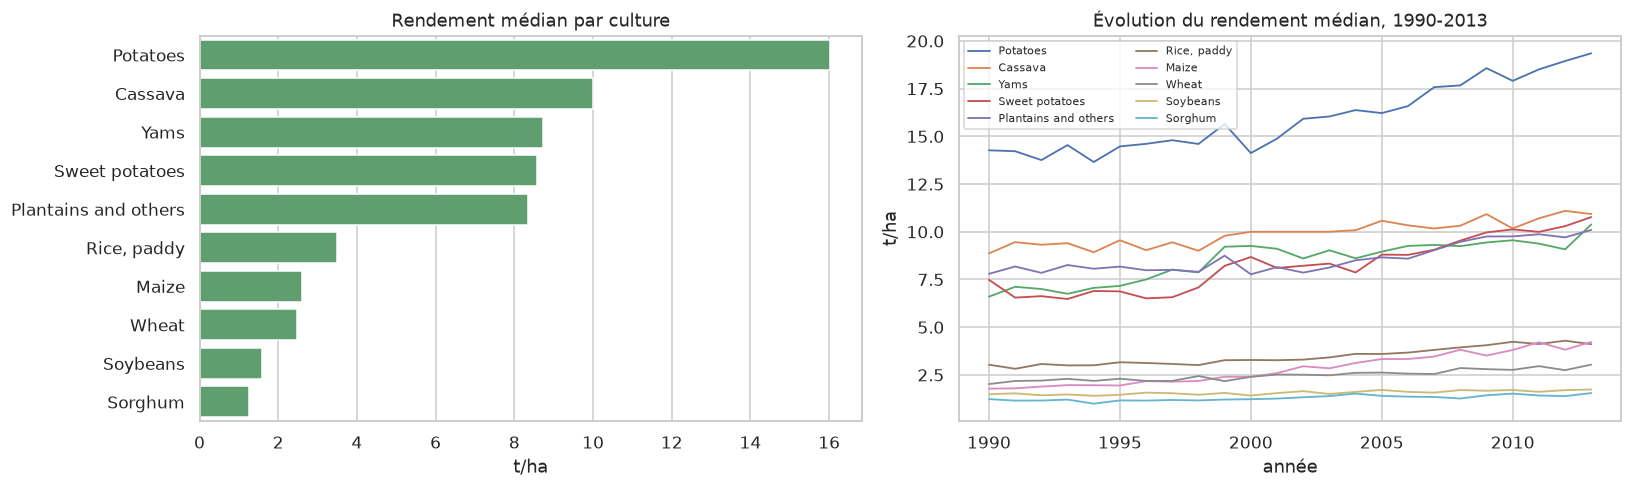

écart entre la culture la plus et la moins productive : facteur 12.7


In [14]:
import matplotlib.pyplot as plt

ordre = complet.groupby("crop")["yield_t_ha"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
import seaborn as sns
sns.barplot(data=complet, y="crop", x="yield_t_ha", order=ordre, estimator="median",
            errorbar=None, ax=axes[0], color="#55A868")
axes[0].set_title("Rendement médian par culture")
axes[0].set_xlabel("t/ha")
axes[0].set_ylabel("")

for culture in ordre:
    serie = complet[complet["crop"] == culture].groupby("year")["yield_t_ha"].median()
    axes[1].plot(serie.index, serie.values, label=culture, lw=1.2)
axes[1].set_title("Évolution du rendement médian, 1990-2013")
axes[1].set_xlabel("année")
axes[1].set_ylabel("t/ha")
axes[1].legend(fontsize=7, ncol=2)
utils.enregistre("04_rendement_par_culture")
plt.show()

ecarts = complet.groupby("crop")["yield_t_ha"].median()
print(f"écart entre la culture la plus et la moins productive : "
      f"facteur {ecarts.max()/ecarts.min():.1f}")

**Observations :**

- **Les cultures se distinguent très nettement** : un facteur **12,8** entre la pomme de
  terre (15,96 t/ha) et le sorgho (1,25 t/ha).
- C'est exactement l'information absente du jeu simulé, où les six cultures rendaient
  toutes ≈ 4,65 t/ha.
- Les tubercules (pomme de terre, manioc, igname, patate douce) dominent les céréales,
  ce qui est attendu : on compare des masses fraîches à des grains secs.
- Les tendances temporelles sont régulières et croissantes, sans rupture suspecte.

# Domaine d'apprentissage

Quelles conditions ce dataset couvre-t-il réellement, culture par culture ? Les quantiles
5 % et 95 % décrivent les 90 % centraux observés. L'API de l'étape 3 s'en servira pour
**signaler une saisie inhabituelle sans la refuser** : sortir de ces bornes n'est pas une
erreur, c'est une zone où le modèle a peu appris.

**L'année 2013 est exclue du calcul.** Elle sera réservée au test final de `/recommend`
(étape 2) : aucune information issue de cette année ne doit circuler en amont, pas même
une borne d'interface.

In [15]:
domaine = cyp.domaine_apprentissage(dataset)
print(f"année exclue : {config.ANNEE_TEST} | {len(domaine)} bornes "
      f"({domaine.crop.nunique()} cultures x {domaine.variable.nunique()} variables)")
domaine[domaine.variable == "avg_temp"].round(2).to_string(index=False)

année exclue : 2013 | 40 bornes (10 cultures x 4 variables)


'                crop variable   q05   q95   min   max    n\n             Cassava avg_temp 16.92 27.95  8.67 30.32 1377\n               Maize avg_temp  7.85 27.79  2.59 30.32 2705\nPlantains and others avg_temp 16.70 27.62  8.67 28.26  760\n            Potatoes avg_temp  6.15 27.61 -3.37 30.32 2676\n         Rice, paddy avg_temp  9.24 27.79  2.59 30.32 2069\n             Sorghum avg_temp  8.98 27.81  2.59 30.32 1877\n            Soybeans avg_temp  7.89 27.29  2.59 29.18 1772\n      Sweet potatoes avg_temp 11.81 27.79  8.67 30.32 1644\n               Wheat avg_temp  5.88 27.62 -3.37 30.32 2327\n                Yams avg_temp 16.19 28.06 14.36 29.18  660'

In [16]:
# Overview: the width of the bounds by crop and variable.
pivot = domaine.pivot(index="crop", columns="variable", values=["q05", "q95"])
pivot.round(1)

q05                                      q95                                
variable             avg_temp pesticides_t rain_mm yield_t_ha avg_temp pesticides_t rain_mm yield_t_ha
crop                                                                                                  
Cassava                  16.9          1.6   322.0        2.6     28.0      61337.0  2928.0       19.8
Maize                     7.8          5.0   111.0        0.7     27.8      65425.9  2666.0       10.4
Plantains and others     16.7         10.5  1146.0        2.2     27.6      15994.3  2926.0       21.6
Potatoes                  6.1          4.0    92.0        4.0     27.6      65335.6  2348.0       36.8
Rice, paddy               9.2          2.9   206.0        1.0     27.8      79821.2  2875.0        7.0
Sorghum                   9.0         17.0   125.0        0.3     27.8      81418.4  2592.0        5.3
Soybeans                  7.9         16.0   252.0        0.5     27.3      86221.7  2391.0        2.8
Sweet potatoes           11.8          2.1   228.0        1.7     27.8      75460.8  2702.0       24.1
Wheat                     5.9         17.0    89.0        0.7     27.6      77603.8  2044.0        6.9
Yams                     16.2          1.0   322.0        2.2     28.1      64302.3  3142.0       16.8

**Observations :**

- Les bornes de température sont **agronomiquement cohérentes** : l'igname démarre à
  16,2 °C et le plantain à 16,7 °C — des cultures tropicales — quand la pomme de terre
  descend à 6,2 °C et le blé à 5,9 °C.
- Les minima et maxima sont bien plus larges que les quantiles : c'est voulu. Une borne
  fondée sur les extrêmes serait dictée par quelques pays atypiques.
- Ces intervalles décrivent **les données**, pas la fiabilité du modèle. Une valeur en
  dehors est inhabituelle dans ce jeu ; elle ne prouve pas que la prédiction sera mauvaise.

# Sauvegarde

In [17]:
config.DATA_TRAITE.mkdir(parents=True, exist_ok=True)
dataset.to_csv(config.CROP_YIELD_PREDICTION_CSV, index=False)
print(f"écrit {config.CROP_YIELD_PREDICTION_CSV.relative_to(config.RACINE)} "
      f"({config.CROP_YIELD_PREDICTION_CSV.stat().st_size / 1024**2:.1f} Mo)")

domaine.to_csv(config.DOMAINE_APPRENTISSAGE_CSV, index=False)
print(f"écrit {config.DOMAINE_APPRENTISSAGE_CSV.relative_to(config.RACINE)} "
      f"({len(domaine)} bornes)")

# Read-back check: the artifact must be self-contained.
relu = pd.read_csv(config.CROP_YIELD_PREDICTION_CSV)
assert len(relu) == len(dataset)
assert relu.duplicated(cyp.CLE).sum() == 0
print(f"relu : {len(relu):,} lignes x {relu.shape[1]} colonnes, clé unique")

écrit data/processed/crop_yield_prediction.csv (1.3 Mo)
écrit data/processed/domaine_apprentissage.csv (40 bornes)
relu : 25,527 lignes x 8 colonnes, clé unique


# Conclusion

- Dataset reconstruit à la granularité **pays × année × culture** : **25 527 lignes**,
  **203 pays**, 10 cultures, 1990-2013.
- **Aucun fan-out** : chaque jointure est vérifiée, et la clé finale est unique.
- **120 pays** appariés sur les quatre sources contre 101 par nom littéral, avec tous les
  grands producteurs — États-Unis, Chine, Russie, Inde, Brésil, Turquie — désormais
  présents.
- **15 794 lignes complètes** (61,9 %) pour 119 pays. Les `NaN` sont conservés plutôt
  qu'imputés.
- **Les cultures sont nettement différenciées** (facteur 12,8), ce qui fournit l'effet
  culture introuvable dans le jeu simulé.

Reste à savoir si ces deux jeux peuvent se combiner, et comment : c'est l'objet du
notebook 05.

## Ce que ce notebook ajoute pour la suite

- **La nature des valeurs manquantes est établie** : tout ou rien pour la température et
  les pesticides, trous isolés pour la pluie — deux traitements opposés, instruits au
  notebook 06.
- **Le domaine d'apprentissage est borné** par culture et par variable
  (`data/processed/domaine_apprentissage.csv`), hors année 2013. L'API de l'étape 3 s'en
  servira pour signaler une saisie inhabituelle sans la refuser.
